<a href="https://colab.research.google.com/github/Takilakm/ml-data-project/blob/main/code/run_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmark Refinement Ladder

**CSI 4170/5170 — Machine Learning, Fall 2026 · Oakland University**  
Jing Yee · Christina Carvalho · Pablo Avila

---

This notebook answers **requirement 2** of the project brief: preprocessing and
feature selection that *measurably* improves the metrics of three algorithms.

It runs on the public benchmark only — the Wisconsin Diagnostic Breast Cancer
dataset, which ships inside scikit-learn. **No data file is needed.** The same
notebook will later run on our own logs by changing one line.

Each stage of the ladder adds one refinement and keeps the previous ones, so the
output table shows exactly what each step was worth:

| stage | what is added |
|---|---|
| 0 | baseline — raw features, default settings |
| 1 | + feature scaling |
| 2 | + outlier removal (training data only) |
| 3 | + feature selection |
| 4 | + hyperparameter tuning |

Everything is evaluated on the **same held-out test set**, so the numbers are
directly comparable. All fitting happens inside a `Pipeline`, so nothing learned
from the test set leaks into training.

## 1 · Fetch the project code

Pulls `pipeline.py` and `refinement.py` straight from our GitHub repository, so
everyone runs the identical code and nobody has to upload anything.

In [2]:
import urllib.request, os

REPO = "https://raw.githubusercontent.com/Takilakm/ml-data-project/main/code/"

for f in ["pipeline.py", "refinement.py"]:
    urllib.request.urlretrieve(REPO + f, f)
    print("downloaded", f)

exec(open("pipeline.py").read())
exec(open("refinement.py").read())

os.makedirs("results", exist_ok=True)
print("\nready")

downloaded pipeline.py
downloaded refinement.py
Benchmark: 569 rows, 30 features
Classes  : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Raw value range: 0.0 to 4254.0   <- very different scales, so preprocessing matters here

Benchmark (Wisconsin breast cancer)  | train: (455, 30)  test: (114, 30)

Naive Bayes
  test accuracy : 0.93
  5-fold CV     : 0.932 +/- 0.004
  confusion matrix (rows = true, cols = predicted):
[[38  4]
 [ 4 68]]

Logistic Regression
  test accuracy : 0.982
  5-fold CV     : 0.98 +/- 0.013
  confusion matrix (rows = true, cols = predicted):
[[41  1]
 [ 1 71]]

SVM (RBF)
  test accuracy : 0.982
  5-fold CV     : 0.971 +/- 0.018
  confusion matrix (rows = true, cols = predicted):
[[41  1]
 [ 1 71]]

SUMMARY
                            dataset               model  accuracy  precision  recall    f1  cv_mean  cv_std
Benchmark (Wisconsin breast cancer)         Naive Bayes     0.930      0.925   0.925 0.925    0.932   0.004
Benchmark (Wiscons

## 2 · Load and inspect the benchmark

Before modelling anything, confirm what we are working with: how many rows, how
many features, whether the classes are balanced, and what range the raw values
span. That last number is the reason scaling matters here.

In [3]:
X, y = load_benchmark()

Benchmark: 569 rows, 30 features
Classes  : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Raw value range: 0.0 to 4254.0   <- very different scales, so preprocessing matters here



## 3 · Baseline — three algorithms, no refinement

This is the "before" column. Three algorithms named in the course learning
outcomes: Naive Bayes, Logistic Regression, and an RBF-kernel SVM.

Confusion matrices are printed as **rows = true class, columns = predicted**.

In [4]:
baseline = run_pipeline(X, y, "Benchmark (Wisconsin breast cancer)")
print("SUMMARY")
print(baseline.to_string(index=False))

Benchmark (Wisconsin breast cancer)  | train: (455, 30)  test: (114, 30)

Naive Bayes
  test accuracy : 0.93
  5-fold CV     : 0.932 +/- 0.004
  confusion matrix (rows = true, cols = predicted):
[[38  4]
 [ 4 68]]

Logistic Regression
  test accuracy : 0.982
  5-fold CV     : 0.98 +/- 0.013
  confusion matrix (rows = true, cols = predicted):
[[41  1]
 [ 1 71]]

SVM (RBF)
  test accuracy : 0.982
  5-fold CV     : 0.971 +/- 0.018
  confusion matrix (rows = true, cols = predicted):
[[41  1]
 [ 1 71]]

SUMMARY
                            dataset               model  accuracy  precision  recall    f1  cv_mean  cv_std
Benchmark (Wisconsin breast cancer)         Naive Bayes     0.930      0.925   0.925 0.925    0.932   0.004
Benchmark (Wisconsin breast cancer) Logistic Regression     0.982      0.981   0.981 0.981    0.980   0.013
Benchmark (Wisconsin breast cancer)           SVM (RBF)     0.982      0.981   0.981 0.981    0.971   0.018


## 4 · The refinement ladder

Now the five stages, for all three algorithms.

> **Note on the convergence warning.** At stage 0 Logistic Regression may warn
> that it did not converge. That is not a bug — it is the unscaled data causing
> the solver to struggle, and it is direct evidence for why stage 1 exists. The
> warning disappears once scaling is applied.

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ladder = refinement_ladder(X, y,
                           "Benchmark (Wisconsin breast cancer)",
                           select_k=15)

Benchmark (Wisconsin breast cancer)  | train (455, 30)  test (114, 30)  | outliers dropped from train: 62  | features kept at stage 3+: 15 of 30

Naive Bayes
                  stage  accuracy  precision  recall    f1
           0 · baseline     0.939      0.936   0.932 0.934
          1 · + scaling     0.930      0.925   0.925 0.925
  2 · + outlier removal     0.904      0.893   0.909 0.899
3 · + feature selection     0.895      0.884   0.902 0.890
           4 · + tuning     0.895      0.884   0.902 0.890
   F1 change from baseline to final: -0.044

Logistic Regression
                  stage  accuracy  precision  recall    f1
           0 · baseline     0.965      0.962   0.962 0.962
          1 · + scaling     0.982      0.981   0.981 0.981
  2 · + outlier removal     0.982      0.981   0.981 0.981
3 · + feature selection     0.965      0.962   0.962 0.962
           4 · + tuning     0.965      0.962   0.962 0.962
   F1 change from baseline to final: +0.000

SVM (RBF)
              

## 5 · Before vs after, side by side

The pivot below is the table that goes into the Phase 2 report.

In [6]:
import pandas as pd

f1_by_stage = ladder.pivot(index="stage", columns="model", values="f1")
print("MACRO F1 BY STAGE")
print(f1_by_stage.to_string())

print("\n\nBASELINE vs FINAL")
summary = pd.DataFrame({
    "baseline (stage 0)": f1_by_stage.iloc[0],
    "final (stage 4)":    f1_by_stage.iloc[-1],
    "best stage":         f1_by_stage.idxmax(),
    "best F1":            f1_by_stage.max(),
})
summary["change"] = (summary["final (stage 4)"] - summary["baseline (stage 0)"]).round(3)
print(summary.to_string())

MACRO F1 BY STAGE
model                    Logistic Regression  Naive Bayes  SVM (RBF)
stage                                                               
0 · baseline                           0.962        0.934      0.923
1 · + scaling                          0.981        0.925      0.981
2 · + outlier removal                  0.981        0.899      0.991
3 · + feature selection                0.962        0.890      0.953
4 · + tuning                           0.962        0.890      0.962


BASELINE vs FINAL
                     baseline (stage 0)  final (stage 4)             best stage  best F1  change
model                                                                                           
Logistic Regression               0.962            0.962          1 · + scaling    0.981   0.000
Naive Bayes                       0.934            0.890           0 · baseline    0.934  -0.044
SVM (RBF)                         0.923            0.962  2 · + outlier removal    0.991   

## 6 · Plot the ladder

One line per algorithm. A line that goes **up** is a refinement that helped; a
line that goes **down** is one that hurt. Both are findings worth reporting.

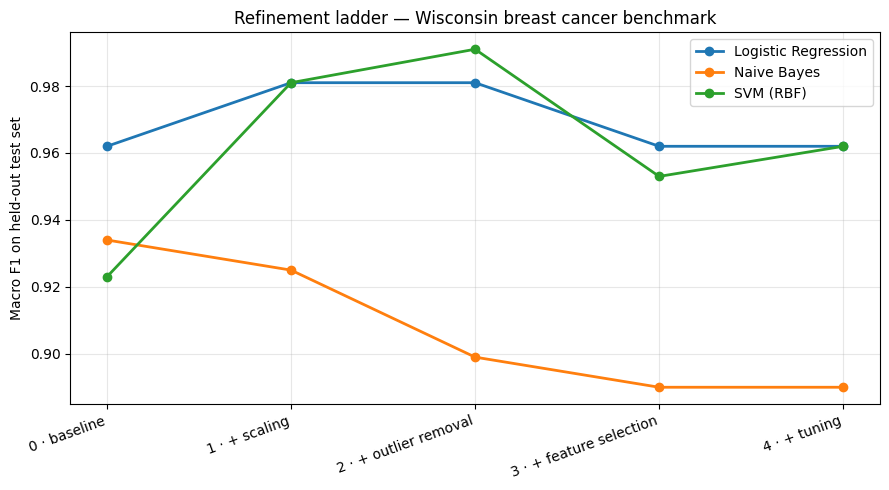

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
for model in f1_by_stage.columns:
    ax.plot(range(len(f1_by_stage)), f1_by_stage[model],
            marker="o", linewidth=2, label=model)

ax.set_xticks(range(len(f1_by_stage)))
ax.set_xticklabels(f1_by_stage.index, rotation=20, ha="right")
ax.set_ylabel("Macro F1 on held-out test set")
ax.set_title("Refinement ladder — Wisconsin breast cancer benchmark")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("results/refinement_ladder.png", dpi=150)
plt.show()

## 7 · Which features did selection keep?

Stage 3 drops half the features. This shows which 15 survived and how strongly
each one separates the classes — useful for explaining *why* the stage behaved
the way it did.

In [8]:
from sklearn.datasets import load_breast_cancer

names = load_breast_cancer().feature_names
feat = which_features(X, y, names, k=15)
print(feat.to_string(index=False))

                feature  F_score  kept
   worst concave points   964.39  True
        worst perimeter   897.94  True
    mean concave points   861.68  True
           worst radius   860.78  True
         mean perimeter   697.24  True
             worst area   661.60  True
            mean radius   646.98  True
              mean area   573.06  True
         mean concavity   533.79  True
        worst concavity   436.69  True
       mean compactness   313.23  True
      worst compactness   304.34  True
           radius error   268.84  True
        perimeter error   253.90  True
             area error   243.65  True
          worst texture   149.60 False
       worst smoothness   122.47 False
         worst symmetry   118.86 False
           mean texture   118.10 False
   concave points error   113.26 False
        mean smoothness    83.65 False
          mean symmetry    69.53 False
worst fractal dimension    66.44 False
      compactness error    53.25 False
        concavity error  

## 8 · Save everything for the repository

Writes three files into `results/` and downloads them. Commit all three to the
repo so the Phase 2 report can cite them.

In [9]:
ladder.to_csv("results/benchmark_refinement_ladder.csv", index=False)
baseline.to_csv("results/benchmark_baseline.csv", index=False)
f1_by_stage.to_csv("results/benchmark_f1_by_stage.csv")

for f in sorted(os.listdir("results")):
    print(f, " -- ", os.path.getsize("results/" + f), "bytes")

benchmark_baseline.csv  --  314 bytes
benchmark_f1_by_stage.csv  --  227 bytes
benchmark_refinement_ladder.csv  --  1524 bytes
refinement_ladder.png  --  105734 bytes


In [10]:
# Colab only — downloads the four files to your computer.
# Skip this cell if you are not on Colab.
try:
    from google.colab import files
    for f in sorted(os.listdir("results")):
        files.download("results/" + f)
except ImportError:
    print("Not on Colab — the files are in the results/ folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9 · What to commit

Upload these into the repository's `results/` folder:

- `benchmark_refinement_ladder.csv` — every stage, every algorithm, all four metrics
- `benchmark_baseline.csv` — the baseline run with cross-validation scores
- `benchmark_f1_by_stage.csv` — the pivot table used in the report
- `refinement_ladder.png` — the figure

---

### Later: running the same ladder on our own logs

When the daily log is ready, the only change is the data going in. The pipeline,
the stages and the metrics all stay identical — that is the design of the study.

```python
url = REPO.replace('/code/', '/data/') + 'daily_log_anonymised.csv'
X_ours, y_ours = load_our_logs(url)
ladder_ours = refinement_ladder(X_ours, y_ours, 'Our daily logs', select_k=3)
```